# Serie II · Fábrica — 06. Calidad de los datos y de los sensores

**Pregunta 1 de la prueba:** evaluar la confiabilidad de cada sensor y de los archivos entregados; identificar sensores
redundantes, faltantes o con comportamiento sospechoso, y explicar cómo se tratan.

**Qué caldera es.** La figura que acompaña los datos y la publicación de origen (Cao et al., 2025, *A long-tailed
distribution time-series dataset in boiler equipment*, Springer Nature/figshare) describen una **caldera de lecho
fluidizado circulante (CFB) a carbón** de una planta química en Zhejiang, China: hogar con dos ciclones, cámaras de
retorno de sólidos, sobrecalentadores con dos atemperadores, economizadores y precalentadores de aire. Las magnitudes
(≈60 t/h de vapor, ≈9.8 MPa en el domo, ≈540 °C) corresponden a una unidad típica de 75 t/h.

**Qué se traslada al ingenio.** Las calderas de bagazo no son de lecho fluidizado, pero comparten lo esencial: aire
primario y secundario, oxígeno en gases, tiro inducido, atemperación y vapor principal. Lo que se traslada es el
**método** (auditar archivos, redundancias y actualización real de cada sensor antes de modelar), no los valores.

**Regla del análisis.** Nada se borra ni se interpola por defecto. Lo raro pero físicamente posible se conserva: la
pregunta 4 lo necesita para detectar anomalías.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from fabrica_datos import (SENSORES, PRESION_HOGAR, PERIODO_S, cargar, revisar_diccionario, comparar_archivos,
                           auditoria_sensores, picos_aislados, tramos_constantes, banderas, variables_derivadas,
                           EXCLUIR_MODELOS)

RAW = ROOT / "data" / "raw" / "serie2"
FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
for d in (FIG, TAB, MOD): d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()

DF = cargar(RAW / "data.csv")
AR = cargar(RAW / "data_AutoReg.csv")
print(f"data.csv: {DF.shape[0]:,} filas × {DF.shape[1]} sensores | {DF.index.min()} → {DF.index.max()}")

data.csv: 86,400 filas × 30 sensores | 2022-03-27 14:28:54 → 2022-04-01 14:28:49


## 1. Los archivos entregados

### 1.1 `data.csv` contra `data_AutoReg.csv`
Los dos archivos pesan casi lo mismo. Se comparan celda por celda.

In [2]:
dif = comparar_archivos(DF, AR)
print(f"Celdas distintas: {len(dif)} de {DF.size:,} | sensores: {dif['sensor'].unique().tolist()}")
huecos = (dif["fecha"].diff() != pd.Timedelta(seconds=PERIODO_S)).cumsum()
tramos_dif = dif.groupby(huecos).agg(desde=("fecha", "min"), hasta=("fecha", "max"), filas=("fecha", "size"),
                                     relleno_min=("otro", "min"), relleno_max=("otro", "max"))
display(tramos_dif)
c = "YJJWSLL"
lineal = DF[c].interpolate()
print(f"Faltantes en data.csv: {int(DF.isna().sum().sum())} (todos en {c}); en data_AutoReg.csv: {int(AR.isna().sum().sum())}")
print(f"Diferencia máxima entre el relleno AutoReg y una interpolación lineal: {(AR[c] - lineal).abs().max():.2f} t/h")
fin2 = tramos_dif["hasta"].iloc[-1]
print(f"Segundo hueco: el relleno termina en {AR.at[fin2, c]:.2f} t/h y el dato medido siguiente es "
      f"{DF[c].iloc[DF.index.get_loc(fin2) + 1]:.2f} t/h")

Celdas distintas: 30 de 2,592,000 | sensores: ['YJJWSLL']


,desde,hasta,filas,relleno_min,relleno_max
fecha,,,,,
1,2022-03-28 06:22:24,2022-03-28 06:24:39,28,1.71,1.86
2,2022-03-30 05:54:44,2022-03-30 05:54:49,2,2.01,2.02


Faltantes en data.csv: 30 (todos en YJJWSLL); en data_AutoReg.csv: 0
Diferencia máxima entre el relleno AutoReg y una interpolación lineal: 1.25 t/h
Segundo hueco: el relleno termina en 2.02 t/h y el dato medido siguiente es 3.90 t/h


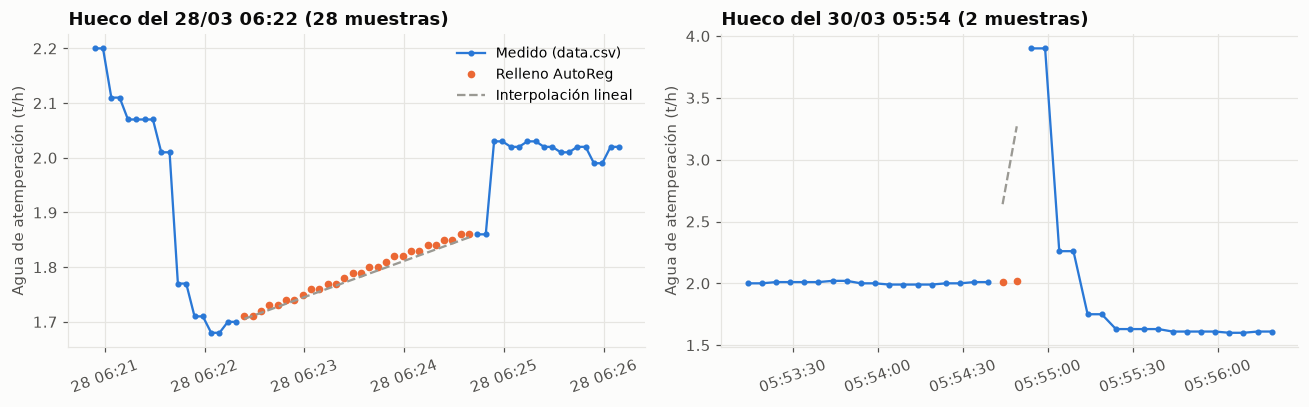

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (_, t) in zip(axs, tramos_dif.iterrows()):
    w = slice(t["desde"] - pd.Timedelta("90s"), t["hasta"] + pd.Timedelta("90s"))
    falta = DF.loc[w, c].isna()
    ax.plot(DF.loc[w, c].index, DF.loc[w, c], color=AZUL, marker="o", ms=3, lw=1.5, label="Medido (data.csv)")
    ax.plot(AR.loc[w, c][falta].index, AR.loc[w, c][falta], color=NARANJA, marker="o", ms=4, lw=0, label="Relleno AutoReg")
    ax.plot(lineal.loc[w][falta].index, lineal.loc[w][falta], color=GRIS, ls="--", lw=1.5, label="Interpolación lineal")
    ax.set_title(f"Hueco del {t['desde']:%d/%m %H:%M} ({int(t['filas'])} muestras)", loc="left")
    ax.set_ylabel("Agua de atemperación (t/h)"); ax.tick_params(axis="x", rotation=20)
axs[0].legend(frameon=False, fontsize=9)
guardar(fig, "serie2_01_archivos.png")

**Lectura.** `data_AutoReg.csv` es `data.csv` con 30 valores inventados en el agua de atemperación: un hueco de 28
muestras (2.3 min) y otro de 2. El relleno autorregresivo **prolonga la tendencia previa**: en el segundo hueco sigue
en ~2 t/h cuando el valor real siguiente salta a 3.9 t/h. No agrega información y puede inventar un comportamiento que
no ocurrió. **Decisión:** se trabaja con `data.csv`; los 30 faltantes quedan como faltantes (0.03 % de un sensor) y los
promedios por ventana los ignoran.

### 1.2 El diccionario `columns.csv`

In [4]:
dic = revisar_diccionario(RAW / "columns.csv", DF.columns.tolist())
for k in ["encabezado", "campos_por_fila", "columna_vacia", "fin_de_linea_windows", "mismos_sensores", "mismo_orden", "con_unidades"]:
    print(f"{k:22s} {dic[k]}")
tabla_dic = pd.DataFrame({"descripción original": pd.Series(dic["descripciones"]),
                          "descripción corregida": {k: v[0] for k, v in SENSORES.items()},
                          "unidad inferida": {k: v[1] for k, v in SENSORES.items()}}).loc[DF.columns]
display(tabla_dic)

encabezado             ['Variant', 'Attribute name', 'Description']
campos_por_fila        2
columna_vacia          ['Description']
fin_de_linea_windows   True
mismos_sensores        True
mismo_orden            False
con_unidades           False


,descripción original,descripción corregida,unidad inferida
PT_8313A,Upper furnace pressure (A),Presión de hogar superior A,Pa
PT_8313B,Upper furnace pressure (B),Presión de hogar superior B,Pa
PT_8313C,Upper furnace pressure (C),Presión de hogar superior C,Pa
PT_8313D,Upper furnace pressure (D),Presión de hogar superior D,Pa
PT_8313E,Upper furnace pressure (E),Presión de hogar superior E,Pa
PT_8313F,Upper furnace pressure (F),Presión de hogar superior F,Pa
PTCA_8322A,Pot pressure (left),Presión del domo (izq.),MPa
PTCA_8324,Container outlet vapour pressure,Presión de vapor a la salida del colector,MPa
TE_8319A,Flue gas temperature at the upper economizer o...,Temperatura de gases a la salida del economiza...,°C
TE_8319B,Flue gas temperature at the upper economizer o...,Temperatura de gases a la salida del economiza...,°C


**Problemas del diccionario:**
- El encabezado anuncia tres columnas (`Variant`, `Attribute name`, `Description`) pero cada fila trae dos: la
  descripción queda bajo "Attribute name" y "Description" queda vacía.
- **No trae unidades.** Se infirieron de las magnitudes: presiones de hogar en Pa (tiro balanceado, negativas), domo
  y colector en MPa, flujos de aire en Nm³/h, vapor y agua en t/h, O₂ en % vol, corriente en A. La unidad de la
  vibración (mm/s o µm) no se puede confirmar.
- Nombres distintos a los del archivo de datos (sufijo `.AV_0#`) y en otro orden.
- Traducciones que confunden: "Pot pressure" es la **presión del domo**; "Container outlet" es el **colector** de
  salida; `TV_8329ZC` se describe como una temperatura, pero es la **apertura de una válvula** (%).
- `ZZQBCHLL` es "flujo de vapor **después de compensación**": ya es un cálculo (el medidor corrige por presión y
  temperatura), no una medición directa. Para la pregunta 3 importa: se va a estimar un valor calculado.

### 1.3 El reloj

In [5]:
paso = DF.index.to_series().diff().dt.total_seconds()
print(f"Filas: {len(DF):,} | pasos de 5 s: {(paso == 5).sum():,} | otros pasos: {(paso.dropna() != 5).sum()} | "
      f"fechas repetidas: {DF.index.duplicated().sum()}")

Filas: 86,400 | pasos de 5 s: 86,399 | otros pasos: 0 | fechas repetidas: 0


**Lectura.** 86,400 filas exactas, todas a 5 s, sin huecos ni repeticiones. Un historiador real casi nunca entrega eso:
el archivo **fue remuestreado** por quien lo publicó (los autores dicen que lo preprocesaron). Consecuencia en la
sección 2: no todos los sensores se midieron cada 5 s.

## 2. Calidad de cada sensor

Para cada sensor: faltantes, rango, cada cuánto cambia de verdad, resolución, el tramo más largo sin cambiar y los
picos de 1-2 muestras (residuo contra la mediana móvil de 1 min mayor que 8 desvíos).

In [6]:
AUD = auditoria_sensores(DF)
display(AUD.drop(columns=["descripcion", "grupo"]).round(2))
AUD.to_csv(TAB / "serie2_auditoria_sensores.csv")
cada10 = AUD.index[AUD["actualiza_s"] == 10].tolist()
print("Se actualizan cada 10 s (el valor se repite en la fila siguiente):", cada10)

,unidad,faltantes,min,p01,mediana,p99,max,actualiza_s,resolucion,valores_distintos,pct_repetido,congelado_max_min,picos_aislados
sensor,,,,,,,,,,,,,
PT_8313A,Pa,0,-484.70,-292.93,-135.32,-24.96,75.33,5,0.08,4132,0.35,0.25,5
PT_8313B,Pa,0,-549.57,-335.39,-186.76,-78.16,51.83,5,0.08,4038,0.48,0.25,13
PT_8313C,Pa,0,-509.12,-287.22,-151.43,-49.63,126.28,5,0.08,3826,0.58,0.25,27
PT_8313D,Pa,0,-501.23,-250.71,-116.52,-12.87,256.53,5,0.08,3874,0.42,0.17,27
PT_8313E,Pa,0,-586.83,-310.64,-165.36,-53.24,245.11,5,0.08,4145,0.51,0.25,33
PT_8313F,Pa,0,-562.75,-296.87,-154.96,-44.01,174.87,5,0.08,4033,0.61,0.25,23
PTCA_8322A,MPa,0,9.42,9.54,9.77,9.93,10.09,5,0.01,68,78.92,4.83,0
PTCA_8324,MPa,0,9.06,9.20,9.45,9.60,9.77,5,0.01,72,78.12,3.67,0
TE_8319A,°C,0,342.53,344.24,357.30,369.17,376.50,5,0.01,2883,43.79,2.83,0


Se actualizan cada 10 s (el valor se repite en la fila siguiente): ['SXLTCYZ', 'SXLTCYY', 'ZCLCCY', 'YCLCCY', 'ZZQBCHLL']


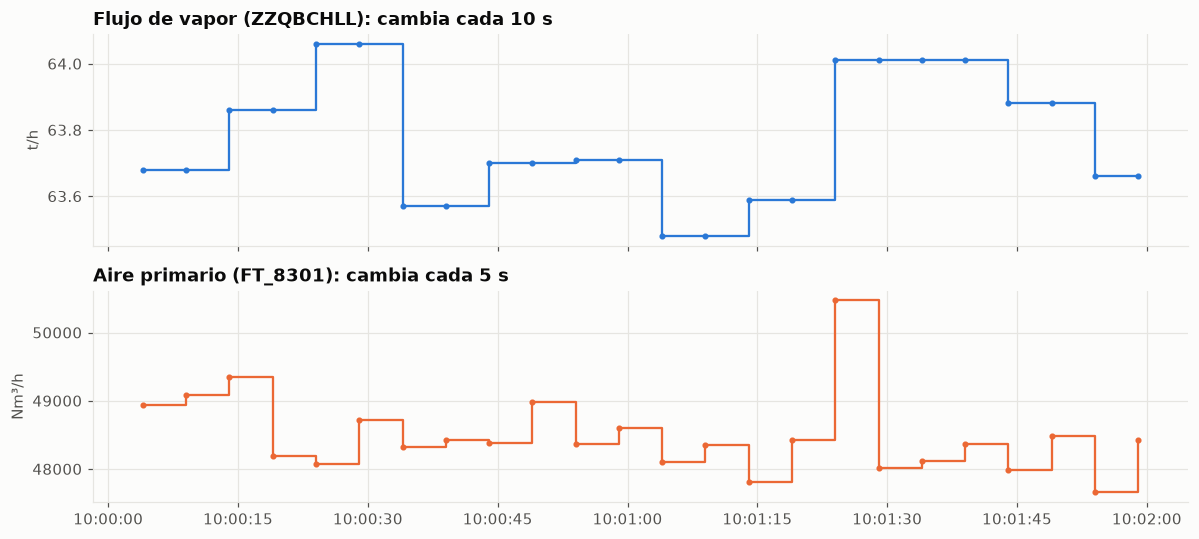

In [7]:
w = slice(pd.Timestamp("2022-03-28 10:00:00"), pd.Timestamp("2022-03-28 10:02:00"))
fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axs[0].step(DF.loc[w].index, DF.loc[w, "ZZQBCHLL"], where="post", color=AZUL, lw=1.5)
axs[0].plot(DF.loc[w].index, DF.loc[w, "ZZQBCHLL"], "o", color=AZUL, ms=3)
axs[0].set_title("Flujo de vapor (ZZQBCHLL): cambia cada 10 s", loc="left"); axs[0].set_ylabel("t/h")
axs[1].step(DF.loc[w].index, DF.loc[w, "FT_8301"], where="post", color=NARANJA, lw=1.5)
axs[1].plot(DF.loc[w].index, DF.loc[w, "FT_8301"], "o", color=NARANJA, ms=3)
axs[1].set_title("Aire primario (FT_8301): cambia cada 5 s", loc="left"); axs[1].set_ylabel("Nm³/h")
guardar(fig, "serie2_02_actualizacion.png")

**Lectura de la tabla:**
- **Cinco sensores se actualizan cada 10 s**, entre ellos el flujo de vapor que pide estimar la pregunta 3. Cambian
  solo en filas pares: la fila impar repite el valor anterior. A 5 s, la mitad de esas filas no es información nueva;
  los modelos trabajan a 10 s o con promedios de 1 min.
- **Resolución gruesa en las presiones de vapor:** pasos de 0.01 MPa y solo ~70 valores distintos en 5 días. Sirven
  para tendencias, no para cambios finos.
- **Faltantes:** solo los 30 del agua de atemperación.
- **Rangos:** todo es físicamente posible. Dos cosas llaman la atención y se conservan para la pregunta 4: el O₂ baja
  hasta 0.8 % y la presión de hogar llega a +256 Pa (el hogar trabaja en depresión; una presión positiva es un golpe
  que empuja gases hacia afuera).
- **Picos de 1-2 muestras:** los hay sobre todo en la corriente del tiro inducido y en la válvula del atemperador. Se
  revisan abajo.

### 2.1 ¿Los picos de la corriente del tiro inducido son errores?
Una corriente de motor que salta ~5 A por 5 s y regresa parece un error de transmisión. Antes de borrarlos se mira
qué hace la presión del hogar alrededor de cada pico.

Picos: 360 (72 por día) | salto mediano 5.1 A | hacia arriba 240, hacia abajo 120
Cambio de presión de hogar en los 10 s siguientes al pico: 9.6 Pa por muestra vs 3.5 Pa en momentos al azar
Presión media en el pico: -139 Pa (arriba) | -200 Pa (abajo) | -155 Pa (azar)


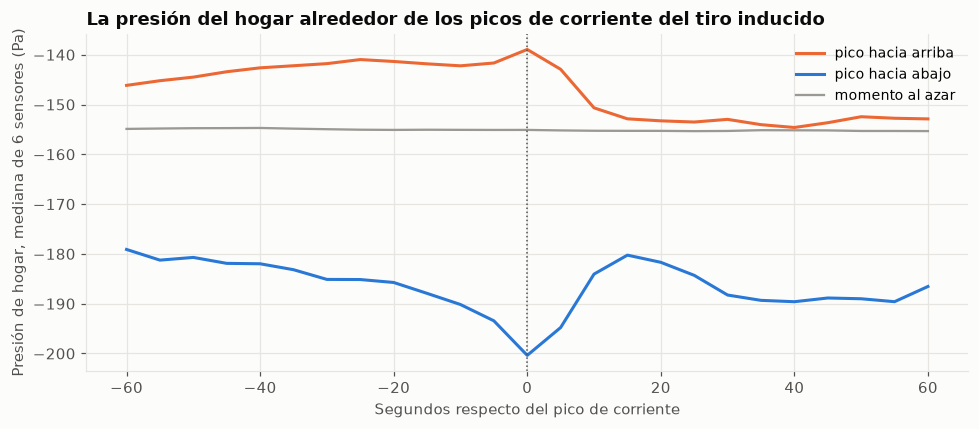

In [8]:
pico = picos_aislados(DF["YFJ3_AI"]).to_numpy()
ph = DF[PRESION_HOGAR].median(axis=1).to_numpy()
corr = DF["YFJ3_AI"].to_numpy(); med = DF["YFJ3_AI"].rolling(13, center=True, min_periods=3).median().to_numpy()
idx = np.where(pico)[0]; idx = idx[(idx > 24) & (idx < len(DF) - 24)]
arriba = corr[idx] > med[idx]
rng = np.random.default_rng(20261019); azar = rng.integers(24, len(DF) - 24, 20000)
lags = np.arange(-12, 13)
perfil = pd.DataFrame({"pico hacia arriba": [np.mean(ph[idx[arriba] + L]) for L in lags],
                       "pico hacia abajo": [np.mean(ph[idx[~arriba] + L]) for L in lags],
                       "momento al azar": [np.mean(ph[azar + L]) for L in lags]}, index=lags * PERIODO_S)
vel = lambda ii, L: np.median(np.abs(ph[ii + L] - ph[ii + L - 1]))
print(f"Picos: {len(idx)} ({len(idx) / 5:.0f} por día) | salto mediano {np.median(np.abs(corr[idx] - med[idx])):.1f} A | "
      f"hacia arriba {arriba.sum()}, hacia abajo {(~arriba).sum()}")
print(f"Cambio de presión de hogar en los 10 s siguientes al pico: {vel(idx, 1):.1f} Pa por muestra "
      f"vs {vel(azar, 1):.1f} Pa en momentos al azar")
print(f"Presión media en el pico: {perfil.loc[0, 'pico hacia arriba']:.0f} Pa (arriba) | {perfil.loc[0, 'pico hacia abajo']:.0f} Pa (abajo) "
      f"| {perfil.loc[0, 'momento al azar']:.0f} Pa (azar)")

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(perfil.columns, [NARANJA, AZUL, GRIS]):
    ax.plot(perfil.index, perfil[col], color=color, label=col, lw=2 if col != "momento al azar" else 1.5)
ax.axvline(0, color=TINTA2, lw=1, ls=":")
ax.set_xlabel("Segundos respecto del pico de corriente"); ax.set_ylabel("Presión de hogar, mediana de 6 sensores (Pa)")
ax.set_title("La presión del hogar alrededor de los picos de corriente del tiro inducido", loc="left")
ax.legend(frameon=False, fontsize=9)
guardar(fig, "serie2_03_picos_tiro.png")

**Lectura.** Los picos **no son errores**:
- La corriente sube cuando la presión del hogar está más alta (menos negativa) y baja cuando está más baja.
- Justo después del pico, la presión cambia 2.7 veces más rápido que en un momento cualquiera.

Es lo que hace un control de tiro: si el hogar se presuriza, el ventilador de tiro inducido jala más. **Decisión:** se
conservan y se marcan como transitorios del control de tiro. Los modelos usan promedios de 1 min, donde casi
desaparecen. Para la pregunta 4 son información: un golpe de presión con respuesta del tiro es un evento real.

### 2.2 La válvula del atemperador que no se mueve

In [9]:
tv = DF["TV_8329ZC"]; fija = tramos_constantes(tv) >= 30 * 60 // PERIODO_S
gid = tv.ne(tv.shift()).cumsum()[fija]
T = DF[fija].groupby(gid).agg(inicio=("TV_8329ZC", lambda s: s.index.min()), minutos=("TV_8329ZC", lambda s: len(s) * PERIODO_S / 60),
                              apertura=("TV_8329ZC", "first"), agua_rango=("YJJWSLL", lambda s: s.max() - s.min()),
                              vapor_T_rango=("TE_8332A", lambda s: s.max() - s.min()))
print(f"Tramos de 30 min o más con la válvula fija: {len(T)} | horas: {T['minutos'].sum() / 60:.1f} "
      f"({100 * fija.mean():.0f} % del tiempo)")
print(f"Con la válvula fija, el agua de atemperación varía {T['agua_rango'].median():.2f} t/h (mediana del rango por tramo); "
      f"en 5 días su desvío es {DF['YJJWSLL'].std():.2f} t/h")
m1 = DF[["TV_8329ZC", "YJJWSLL"]].resample("1min").mean().diff()
print(f"Correlación entre cambios de 1 min de la válvula y del agua: {m1.corr().iloc[0, 1]:.2f}")
print(f"Temperatura del vapor con la válvula fija: rango mediano de {T['vapor_T_rango'].median():.1f} °C por tramo")

Tramos de 30 min o más con la válvula fija: 17 | horas: 12.0 (10 % del tiempo)
Con la válvula fija, el agua de atemperación varía 0.12 t/h (mediana del rango por tramo); en 5 días su desvío es 0.33 t/h
Correlación entre cambios de 1 min de la válvula y del agua: 0.92
Temperatura del vapor con la válvula fija: rango mediano de 7.0 °C por tramo


**Lectura.** No es una señal congelada. Cuando la válvula no se mueve, el agua tampoco (varía ~0.1 t/h), y cuando se
mueve, el agua la sigue (r = 0.92 en cambios de 1 min). La válvula **se queda quieta de verdad**: 12 h en 17 tramos.
Lo más probable es que el lazo de atemperación esté en manual o sin acción en esos ratos, mientras la temperatura del
vapor se mueve ~7 °C por tramo. Es un hallazgo de operación (pregunta 5), no de calidad de datos.

## 3. Redundancia y consistencia entre sensores

Los sensores repetidos (seis presiones de hogar, pares izquierda-derecha) permiten verificar unos con otros. Se usan
promedios de 1 min para no confundir ruido de muestreo con desacuerdo.

In [10]:
M = DF.resample("1min").mean()
pares = [("PT_8313D", "PT_8313E"), ("PT_8313A", "PT_8313B"), ("PT_8313A", "PT_8313D"), ("ZCLCCY", "YCLCCY"),
         ("AIR_8301A", "AIR_8301B"), ("PTCA_8322A", "PTCA_8324"), ("TE_8319A", "TE_8319B"), ("TE_8303", "TE_8304"),
         ("FT_8306A", "FT_8306B"), ("SXLTCYZ", "SXLTCYY"), ("SXLTCYZ", "PT_8313A"), ("SXLTCYY", "PT_8313A"),
         ("YFJ3_ZD1", "YFJ3_ZD2")]
PAR = pd.DataFrame([{"sensor 1": p, "sensor 2": q, "r (1 min)": M[p].corr(M[q]), "diferencia media": (DF[p] - DF[q]).mean(),
                     "desvío de la diferencia": (DF[p] - DF[q]).std()} for p, q in pares])
display(PAR.round(3))
R = M[PRESION_HOGAR + ["SXLTCYZ", "SXLTCYY"]].corr()
otros = lambda c: M.corr()[c].drop(c).abs().sort_values(ascending=False).head(3).round(2).to_dict()
for c in ["SXLTCYY", "YFJ3_ZD1", "YFJ3_ZD2"]:
    print(f"{c}: sensores más relacionados {otros(c)}")
print("Ruido de muestra a muestra (desvío del cambio de 5 s): ZD1 "
      f"{DF['YFJ3_ZD1'].diff().std():.2f}, ZD2 {DF['YFJ3_ZD2'].diff().std():.2f}")
sesgo = {c: (DF[c] - DF[PRESION_HOGAR].drop(columns=c).median(axis=1)).mean() for c in PRESION_HOGAR}
print("Desplazamiento de cada presión de hogar contra la mediana de las otras cinco (Pa):", {k: round(v) for k, v in sesgo.items()})

,sensor 1,sensor 2,r (1 min),diferencia media,desvío de la diferencia
0,PT_8313D,PT_8313E,0.998,48.920,8.678
1,PT_8313A,PT_8313B,0.992,50.900,11.849
2,PT_8313A,PT_8313D,0.882,-19.273,28.413
3,ZCLCCY,YCLCCY,0.987,56.094,108.313
4,AIR_8301A,AIR_8301B,0.946,-0.145,0.133
5,PTCA_8322A,PTCA_8324,0.948,0.326,0.024
6,TE_8319A,TE_8319B,0.915,-34.089,4.389
7,TE_8303,TE_8304,0.669,-11.380,3.677
8,FT_8306A,FT_8306B,-0.837,81.371,41.436
9,SXLTCYZ,SXLTCYY,0.144,245.447,76.885


SXLTCYY: sensores más relacionados {'FT_8301': 0.37, 'ZZQBCHLL': 0.29, 'TE_8313B': 0.29}
YFJ3_ZD1: sensores más relacionados {'YFJ3_AI': 0.71, 'FT_8302': 0.64, 'ZZQBCHLL': 0.59}
YFJ3_ZD2: sensores más relacionados {'FT_8306B': 0.24, 'FT_8306A': 0.15, 'ZCLCCY': 0.14}
Ruido de muestra a muestra (desvío del cambio de 5 s): ZD1 0.59, ZD2 2.52


Desplazamiento de cada presión de hogar contra la mediana de las otras cinco (Pa): {'PT_8313A': 21, 'PT_8313B': -39, 'PT_8313C': 4, 'PT_8313D': 43, 'PT_8313E': -16, 'PT_8313F': -4}


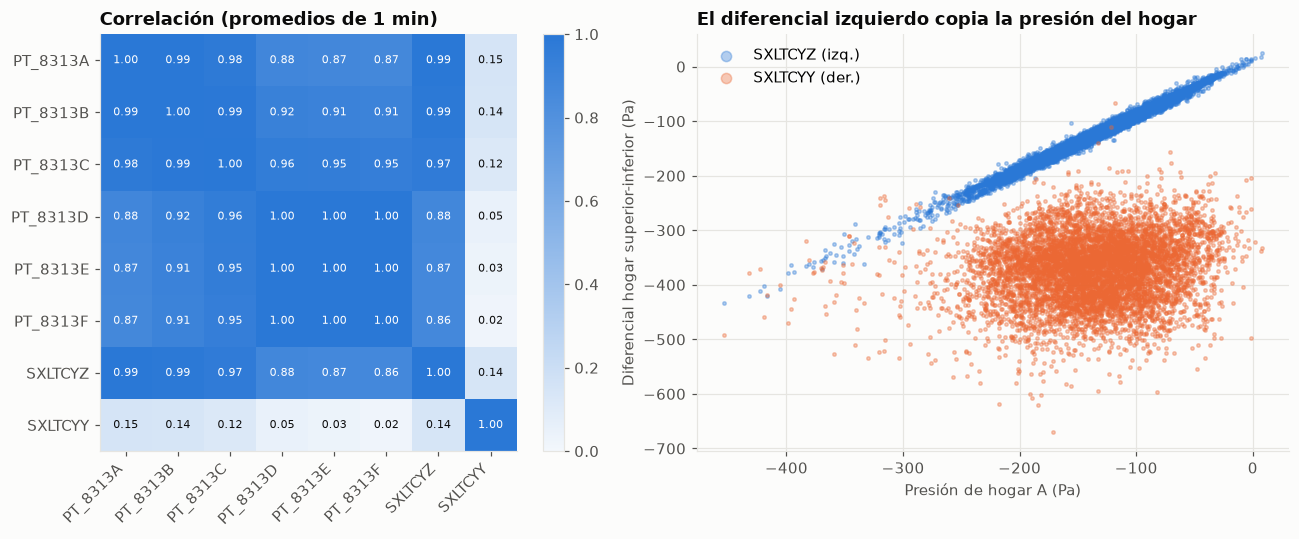

In [11]:
azules = LinearSegmentedColormap.from_list("azules", ["#f3f7fc", AZUL])
fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.1, 1]})
im = axs[0].imshow(R.values, cmap=azules, vmin=0, vmax=1)
axs[0].set_xticks(range(len(R)), R.columns, rotation=45, ha="right"); axs[0].set_yticks(range(len(R)), R.index)
for i in range(len(R)):
    for j in range(len(R)):
        axs[0].text(j, i, f"{R.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if R.values[i, j] > 0.6 else TINTA)
axs[0].grid(False); axs[0].set_title("Correlación (promedios de 1 min)", loc="left")
fig.colorbar(im, ax=axs[0], fraction=0.046, pad=0.04)
axs[1].scatter(M["PT_8313A"], M["SXLTCYZ"], s=5, color=AZUL, alpha=0.35, label="SXLTCYZ (izq.)")
axs[1].scatter(M["PT_8313A"], M["SXLTCYY"], s=5, color=NARANJA, alpha=0.35, label="SXLTCYY (der.)")
axs[1].set_xlabel("Presión de hogar A (Pa)"); axs[1].set_ylabel("Diferencial hogar superior-inferior (Pa)")
axs[1].set_title("El diferencial izquierdo copia la presión del hogar", loc="left"); axs[1].legend(frameon=False, markerscale=3)
guardar(fig, "serie2_04_redundancia.png")

**Lectura:**
- **Presiones de hogar (6 sensores):** forman dos familias, A-B-C y D-E-F. D, E y F son casi idénticas (r ≥ 0.996):
  redundantes. Cada sensor tiene un desplazamiento fijo de hasta ~40 Pa contra la mediana de los demás (calibración).
  **Decisión:** para modelar se usa la **mediana de los seis**, que no se mueve si uno falla. Los seis individuales se
  conservan: con ellos se distingue una falla de sensor de un evento real (pregunta 4).
- **`SXLTCYZ` no mide lo que dice.** Un diferencial entre la parte alta y la baja del hogar depende de los sólidos y
  del aire de fluidización. Este copia la presión del hogar (r = 0.99, a ~12 Pa). Su gemelo derecho `SXLTCYY` no se
  parece a ella (r = 0.14), y su relación más fuerte, débil (r = 0.37), es con el aire primario. Lo más probable es que la toma inferior esté **tapada** (común
  con ceniza) o que el tag esté mal asignado. **Decisión:** fuera de los modelos; se reporta a instrumentación.
- **Vibraciones del tiro inducido:** la chumacera A sigue la carga del ventilador (r ≈ 0.7 con la corriente). La B no
  se relaciona con nada (|r| ≤ 0.24) y su ruido de muestra a muestra es más de cuatro veces mayor. **Decisión:** `YFJ3_ZD2` es
  sospechoso (sensor o montaje); fuera de los modelos, y se verifica con mantenimiento.
- **Pares coherentes:** lecho izquierdo y derecho (r = 0.99), O₂ izquierdo y derecho (0.95), domo y colector (0.95; la
  diferencia estable de 0.33 MPa es la caída de presión del sobrecalentador). **Decisión:** promediar cada par.
- **Gases izquierda y derecha:** se mueven juntos (r = 0.92), pero el derecho está ~34 °C más caliente todo el tiempo.
  Puede ser un desbalance real de gases o un desplazamiento del sensor; con estos datos no se distingue.
- **Aire a las cámaras de retorno:** izquierda y derecha se mueven en espejo (r = −0.84), ver sección 4.

## 4. Cambios que parecen fallas pero son operación

Escalón en el aire de retorno: 30/03 08:53
  FT_8306A: 720 → 677 Nm³/h (-44)
  FT_8306B: 604 → 639 Nm³/h (+35)
  total: 1,324 → 1,315 Nm³/h (-9)


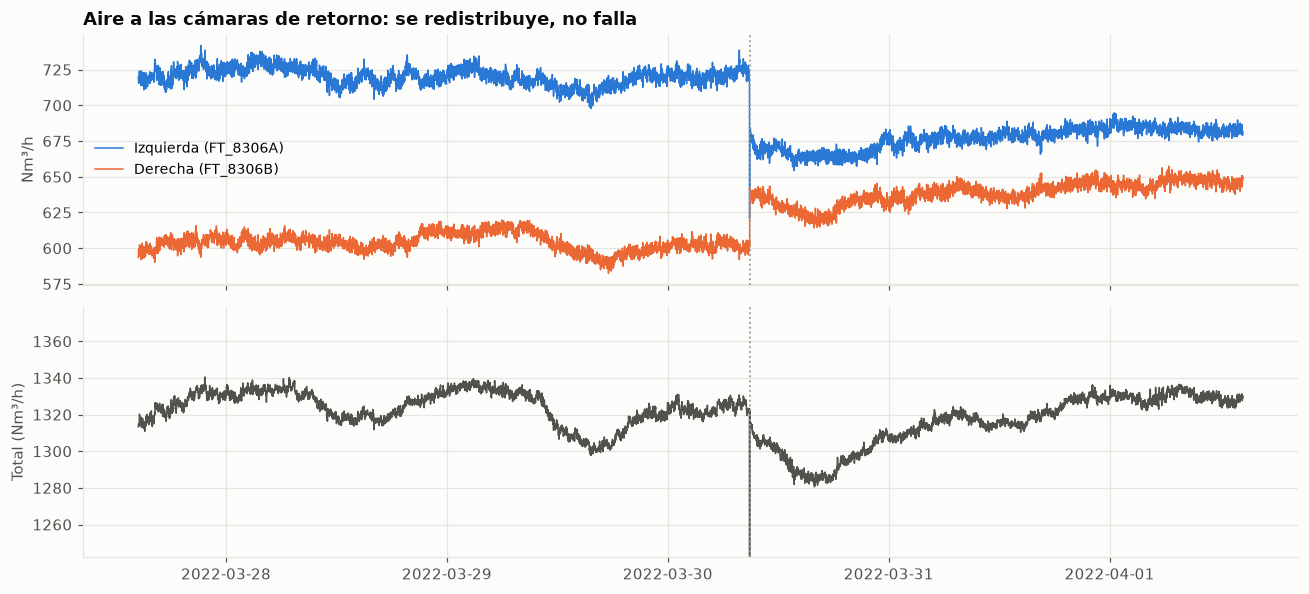

In [12]:
r1 = DF[["FT_8306A", "FT_8306B"]].resample("1min").mean()
r1["total"] = r1.sum(axis=1)
salto = r1["FT_8306A"].diff(5).idxmin()
antes, despues = r1.loc[:salto - pd.Timedelta("10min")], r1.loc[salto + pd.Timedelta("10min"):]
print(f"Escalón en el aire de retorno: {salto:%d/%m %H:%M}")
for col in r1.columns:
    print(f"  {col}: {antes[col].mean():,.0f} → {despues[col].mean():,.0f} Nm³/h ({despues[col].mean() - antes[col].mean():+,.0f})")

fig, axs = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axs[0].plot(r1.index, r1["FT_8306A"], color=AZUL, lw=1, label="Izquierda (FT_8306A)")
axs[0].plot(r1.index, r1["FT_8306B"], color=NARANJA, lw=1, label="Derecha (FT_8306B)")
axs[0].set_ylabel("Nm³/h"); axs[0].legend(frameon=False, fontsize=9, loc="center left")
axs[0].set_title("Aire a las cámaras de retorno: se redistribuye, no falla", loc="left")
axs[1].plot(r1.index, r1["total"], color=TINTA2, lw=1); axs[1].set_ylabel("Total (Nm³/h)")
axs[1].set_ylim(r1["total"].quantile(0.001) - 40, r1["total"].quantile(0.999) + 40)
for ax in axs: ax.axvline(salto, color=GRIS, ls=":", lw=1.2)
guardar(fig, "serie2_05_aire_retorno.png")

**Lectura.** El 30/03 cerca de las 08:53 el aire izquierdo baja y el derecho sube a la vez, y el total casi no cambia. Dos
sensores que fallan al mismo tiempo en sentidos opuestos no conservan la suma: es una **redistribución hecha por el
operador** (compuertas de las cámaras de retorno). Se conserva como evento de operación. La pregunta 2 lo usa como
marca de cambio de régimen.

El ciclo de llenado y descarga del lecho (el "serrucho" del diferencial de lecho) también es operación: se analiza en la
pregunta 2.

## 5. Decisión por sensor

In [13]:
estado = {c: "confiable" for c in DF.columns}
trat = {c: "usar" for c in DF.columns}
for c in ["PT_8313D", "PT_8313E", "PT_8313F", "PT_8313A", "PT_8313B", "PT_8313C"]:
    estado[c] = "redundante (6 presiones de hogar)"; trat[c] = "modelos: mediana de los 6; fallas: cada uno"
for c in ["ZCLCCY", "YCLCCY"]:
    estado[c] = "confiable, actualiza cada 10 s"; trat[c] = "promedio izq./der.; resolución ≥ 10 s"
for c in ["AIR_8301A", "AIR_8301B"]:
    trat[c] = "promedio izq./der."
for c in ["TE_8319A", "TE_8319B"]:
    estado[c] = "confiable; der. +34 °C fijo"; trat[c] = "promedio izq./der.; verificar calibración"
estado["SXLTCYZ"] = "sospechoso: copia la presión de hogar"; trat["SXLTCYZ"] = "fuera de modelos; revisar toma inferior"
estado["SXLTCYY"] = "confiable, actualiza cada 10 s"; trat["SXLTCYY"] = "usar; resolución ≥ 10 s"
estado["YFJ3_ZD2"] = "sospechoso: ruido sin relación"; trat["YFJ3_ZD2"] = "fuera de modelos; verificar con mantenimiento"
estado["YFJ3_AI"] = "confiable, con transitorios de control"; trat["YFJ3_AI"] = "usar en promedios de 1 min; transitorios a la pregunta 4"
estado["YJJWSLL"] = "30 faltantes"; trat["YJJWSLL"] = "dejar faltantes; no usar data_AutoReg.csv"
estado["ZZQBCHLL"] = "calculado (compensado), actualiza cada 10 s"; trat["ZZQBCHLL"] = "objetivo de la pregunta 3; resolución ≥ 10 s"
estado["PTCA_8322A"] = estado["PTCA_8324"] = "confiable, resolución 0.01 MPa"
estado["TV_8329ZC"] = "confiable; 12 h fija (operación)"
estado["FT_8306A"] = estado["FT_8306B"] = "confiable; redistribución 30/03 ~08:53"
TRAT = pd.DataFrame({"descripción": {c: SENSORES[c][0] for c in DF.columns}, "unidad": {c: SENSORES[c][1] for c in DF.columns},
                     "estado": estado, "tratamiento": trat}).loc[DF.columns]
display(TRAT)
TRAT.to_csv(TAB / "serie2_tratamiento_sensores.csv")
print("Conteo:", TRAT["estado"].str.split(":|,|;| \\(").str[0].value_counts().to_dict())

,descripción,unidad,estado,tratamiento
PT_8313A,Presión de hogar superior A,Pa,redundante (6 presiones de hogar),modelos: mediana de los 6; fallas: cada uno
PT_8313B,Presión de hogar superior B,Pa,redundante (6 presiones de hogar),modelos: mediana de los 6; fallas: cada uno
PT_8313C,Presión de hogar superior C,Pa,redundante (6 presiones de hogar),modelos: mediana de los 6; fallas: cada uno
PT_8313D,Presión de hogar superior D,Pa,redundante (6 presiones de hogar),modelos: mediana de los 6; fallas: cada uno
PT_8313E,Presión de hogar superior E,Pa,redundante (6 presiones de hogar),modelos: mediana de los 6; fallas: cada uno
PT_8313F,Presión de hogar superior F,Pa,redundante (6 presiones de hogar),modelos: mediana de los 6; fallas: cada uno
PTCA_8322A,Presión del domo (izq.),MPa,"confiable, resolución 0.01 MPa",usar
PTCA_8324,Presión de vapor a la salida del colector,MPa,"confiable, resolución 0.01 MPa",usar
TE_8319A,Temperatura de gases a la salida del economiza...,°C,confiable; der. +34 °C fijo,promedio izq./der.; verificar calibración
TE_8319B,Temperatura de gases a la salida del economiza...,°C,confiable; der. +34 °C fijo,promedio izq./der.; verificar calibración


Conteo: {'confiable': 20, 'redundante': 6, 'sospechoso': 2, '30 faltantes': 1, 'calculado': 1}


In [14]:
B = banderas(DF)
print("Filas marcadas:", B.sum().to_dict())
artefacto = {
    "descripcion": "Serie II · diccionario corregido y tratamiento de los 30 sensores de la caldera",
    "archivo_base": "data.csv", "periodo_s": PERIODO_S,
    "sensores": {c: {"descripcion": SENSORES[c][0], "unidad": SENSORES[c][1], "grupo": SENSORES[c][2],
                     "actualiza_s": int(AUD.at[c, "actualiza_s"]), "estado": estado[c], "tratamiento": trat[c],
                     "p01": float(AUD.at[c, "p01"]), "p99": float(AUD.at[c, "p99"])} for c in DF.columns},
    "excluir_modelos": EXCLUIR_MODELOS, "presion_hogar": PRESION_HOGAR,
}
(MOD / "serie2_sensores.json").write_text(json.dumps(artefacto, ensure_ascii=False, indent=1), encoding="utf-8")
resumen = {"celdas_distintas_autoreg": int(len(dif)), "faltantes": int(DF.isna().sum().sum()),
           "sensores_cada_10s": cada10, "picos_tiro": int(len(idx)), "horas_valvula_fija": float(T["minutos"].sum() / 60),
           "tramos_valvula_fija": int(len(T)), "salto_retorno": str(salto),
           "r_sxltcyz_pt8313a": float(M["SXLTCYZ"].corr(M["PT_8313A"]))}
(TAB / "serie2_resumen_p1.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1), encoding="utf-8")
print(resumen)

Filas marcadas: {'faltante_agua': 30, 'transitorio_tiro': 361, 'valvula_fija': 8656}
{'celdas_distintas_autoreg': 30, 'faltantes': 30, 'sensores_cada_10s': ['SXLTCYZ', 'SXLTCYY', 'ZCLCCY', 'YCLCCY', 'ZZQBCHLL'], 'picos_tiro': 360, 'horas_valvula_fija': 12.022222222222222, 'tramos_valvula_fija': 17, 'salto_retorno': '2022-03-30 08:53:00', 'r_sxltcyz_pt8313a': 0.9928193995924519}


## Evaluación gerencial

**Qué significa para el ingenio.** Los datos son utilizables, pero no tal como vienen:
- De 30 sensores, 28 se usan, varios con tratamiento especial (ver la tabla de la sección 5). Seis de ellos son
  presiones de hogar redundantes entre sí, lo que es bueno: permiten verificarse unos con otros.
- **Uno no mide lo que dice:** el diferencial izquierdo del hogar copia la presión del hogar.
- **Uno es sospechoso:** la vibración B del tiro inducido no se relaciona con nada.
- Dos tienen particularidades que se manejan sin descartarlos.
- El segundo archivo (`data_AutoReg.csv`) **inventa 30 valores** y no aporta nada.
- El diccionario no trae unidades y describe mal al menos un sensor.
- El flujo de vapor, la variable que se quiere estimar, se actualiza cada 10 s y es un valor calculado.

**Decisión recomendada.**
1. Trabajar con `data.csv` y las reglas de la sección 5, guardadas en `serie2_sensores.json` para que la API y las
   alertas las apliquen igual.
2. Pedir a instrumentación: revisar la toma inferior de `SXLTCYZ` y el sensor B de vibración, y confirmar unidades.
3. En el historiador del ingenio: guardar cada sensor a su frecuencia real, con unidades, y sin rellenar huecos.
   Rellenar es una decisión del análisis, no del archivo.

**Impacto estimado.**
- Evita construir el sensor virtual y las alertas sobre un diferencial que no es diferencial.
- Evita borrar ~70 eventos diarios de respuesta del tiro inducido que parecían errores y son información.
- No se puede expresar en dinero: es la condición para que las preguntas 3 a 5 valgan.

**Riesgos.**
- Las unidades son inferidas.
- El proveedor ya preprocesó los datos y no vemos los originales.
- Cinco días no muestran fallas lentas de sensores (derivas de meses).
- La causa del problema de `SXLTCYZ` (toma tapada o tag mal asignado) solo se confirma en planta.

**Nivel de certeza.**
- Alta en lo determinístico: la diferencia entre archivos, el reloj, la actualización cada 10 s y los problemas del
  diccionario.
- Alta en que `SXLTCYZ` copia la presión de hogar (r = 0.99); media en la causa.
- Media en que `YFJ3_ZD2` es un sensor defectuoso: también podría ser una chumacera con vibración propia.